# 01 · Exploración de los datos

Este notebook revisa la integridad del dataset Bike Sharing de UCI (Capital Bikeshare, Washington D.C., 2011–2012), justifica la limpieza aplicada en `bike_sharing.datos` y describe los patrones de la demanda que orientan a los modelos: tendencia, estacionalidad diaria y semanal, efecto del clima y del calendario, y estacionariedad.

Los últimos 30 días (2012-12-02 a 2012-12-31) se reservan como prueba en todos los notebooks y se marcan en gris en las figuras.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bike_sharing import RANDOM_STATE, datos
from bike_sharing.datos import RAIZ, INICIO_PRUEBA, FIN_PRUEBA

RESULTADOS = RAIZ / "results"
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
np.random.seed(RANDOM_STATE)

## 1. Carga e integridad

`day.csv` trae una fila por día y `hour.csv` una por hora. Ambos se descargan de UCI y se verifican con SHA-256. La revisión busca fechas y horas faltantes, duplicados, nulos y coherencia entre los dos archivos.

In [2]:
day_crudo, hour_crudo = datos.cargar_crudos()
integridad = datos.revisar_integridad(day_crudo, hour_crudo)
faltantes = integridad.pop("horas_faltantes")
pd.Series(integridad, dtype=object).to_frame("valor")

,valor
dias_esperados,731
dias_presentes,731
dias_faltantes,0
dias_duplicados,0
horas_esperadas,17544
horas_presentes,17379
horas_duplicadas,0
nulos_day,0
nulos_hour,0
dias_cnt_distinto,0


La tabla diaria está completa: 731 días, sin duplicados ni nulos. La horaria tiene 17.379 de las 17.544 horas esperadas. Las variables de calendario (`yr`, `mnth`, `weekday`) coinciden con la fecha en los dos archivos, `casual + registered = cnt` en todas las filas y la suma de `cnt` por día en `hour.csv` es igual a `cnt` de `day.csv` en todos los días. Eso dice qué son las horas faltantes: si la suma diaria ya cuadra sin ellas, en esas horas no hubo alquileres.

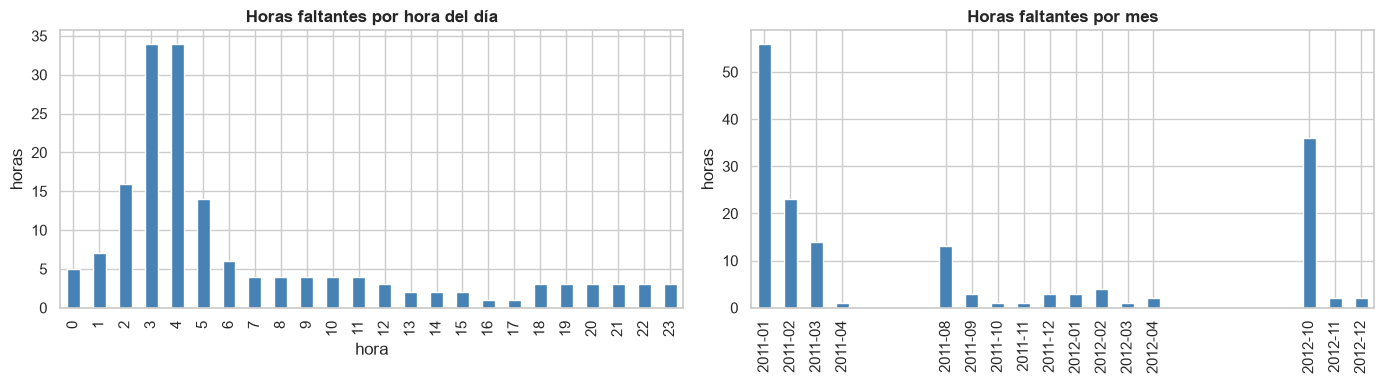

,horas faltantes
timestamp,
2012-10-29,23
2011-01-27,16
2012-10-30,13
2011-01-18,12
2011-01-26,8
2011-08-28,7


In [3]:
huecos = pd.DataFrame({"timestamp": faltantes})
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
huecos["timestamp"].dt.hour.value_counts().sort_index().plot.bar(ax=ejes[0], color="steelblue")
ejes[0].set(title="Horas faltantes por hora del día", xlabel="hora", ylabel="horas")
huecos["timestamp"].dt.to_period("M").value_counts().sort_index().plot.bar(ax=ejes[1], color="steelblue")
ejes[1].set(title="Horas faltantes por mes", xlabel="", ylabel="horas")
plt.tight_layout(); plt.show()

dias_con_mas_huecos = huecos.groupby(huecos["timestamp"].dt.date).size().sort_values(ascending=False).head(6)
dias_con_mas_huecos.rename("horas faltantes").to_frame()

Las horas faltantes se concentran en la madrugada (de 2:00 a 5:00), en enero de 2011, cuando el sistema tenía menos usuarios y hubo una nevada el 26 y 27 de enero, y en el cierre por el huracán Sandy: faltan 23 de las 24 horas del 29 de octubre de 2012 y 13 del 30.

## 2. Limpieza

**Rejilla horaria completa.** Los rezagos y las ventanas móviles de los modelos de machine learning (`shift(24)` = misma hora de ayer) solo son correctos si la serie no tiene huecos. Se reindexa a las 17.544 horas y se imputa cada tipo de variable según su naturaleza:

| Variable | Imputación | Motivo |
| --- | --- | --- |
| `cnt`, `casual`, `registered` | 0 | Las horas ausentes son horas sin alquileres; así la suma diaria sigue igual a `day.csv` |
| `temp`, `atemp`, `hum`, `windspeed` | interpolación lineal | El clima cambia de forma continua entre horas vecinas |
| `weathersit` | último valor observado | La situación del tiempo es categórica y persiste |
| `season`, `holiday`, `workingday` | valor del día en `day.csv` | Son constantes dentro de un día |
| `hr`, `weekday`, `mnth`, `yr` | desde la fecha | Se derivan del índice |

In [4]:
day = datos.serie_diaria()
h = datos.serie_horaria()
print(f"Horas en la rejilla: {len(h):,}  ·  imputadas: {h['imputada'].sum()}  ·  nulos: {h.isna().sum().sum()}")
print("Suma diaria igual a day.csv:", bool((h["cnt"].resample("D").sum() == day_crudo["cnt"]).all()))

Horas en la rejilla: 17,544  ·  imputadas: 165  ·  nulos: 0
Suma diaria igual a day.csv: True


**Desnormalización.** UCI publica el clima normalizado. Para interpretarlo se recuperan las unidades físicas con los rangos del Readme del dataset: temperatura en °C (`temp · 47 − 8`), sensación térmica en °C (`atemp · 66 − 16`), humedad en % (`hum · 100`) y viento en km/h (`windspeed · 67`).

In [5]:
cols_fisicas = ["temp_c", "atemp_c", "hum_pct", "viento_kmh"]
datos.desnormalizar(day_crudo)[cols_fisicas].describe().T

,count,mean,std,min,25%,50%,75%,max
temp_c,731.00,15.28,8.60,-5.22,7.84,15.42,22.80,32.50
atemp_c,731.00,15.31,10.76,-10.78,6.30,16.12,24.17,39.50
hum_pct,731.00,62.79,14.24,0.00,52.00,62.67,73.02,97.25
viento_kmh,731.00,12.76,5.19,1.50,9.04,12.13,15.63,34.00


## 3. Valores atípicos

Los rangos son físicamente plausibles salvo una humedad del 0 %, imposible al aire libre.

In [6]:
crudo_d = datos.desnormalizar(day_crudo)
crudo_h = datos.desnormalizar(hour_crudo)
print("Días con humedad 0 %:", list(crudo_d.index[crudo_d["hum_pct"] == 0].date))
print("Horas con humedad 0 %:", (crudo_h["hum_pct"] == 0).sum(),
      "· todas del", sorted(set(crudo_h.loc[crudo_h["hum_pct"] == 0, "dteday"].dt.date)))
crudo_d.loc["2011-03-08":"2011-03-12", ["weathersit", "temp_c", "hum_pct", "viento_kmh", "cnt"]]

Días con humedad 0 %: [datetime.date(2011, 3, 10)]
Horas con humedad 0 %: 22 · todas del [datetime.date(2011, 3, 10)]


,weathersit,temp_c,hum_pct,viento_kmh,cnt
dteday,,,,,
2011-03-08,1,5.75,42.08,8.08,2133
2011-03-09,2,5.90,77.54,14.75,1891
2011-03-10,3,10.29,0.00,17.55,623
2011-03-11,2,6.88,64.96,15.61,1977
2011-03-12,1,7.47,59.46,14.79,2132


Las 22 horas registradas del 2011-03-10 tienen humedad 0, en un día de lluvia (`weathersit = 3`) con humedades de 60–80 % en los días vecinos: es una falla del sensor, no un dato. En la tabla diaria se reemplaza por la media de los días vecinos y en la horaria se trata como faltante y se interpola.

En la demanda, los días de menor uso tienen una causa conocida y no se eliminan: forman parte de la serie que los modelos deben pronosticar.

In [7]:
q1, q3 = day["cnt"].quantile([0.25, 0.75])
limite = q1 - 1.5 * (q3 - q1)
print(f"Límite inferior de Tukey: {limite:,.0f} alquileres/día")
day.nsmallest(6, "cnt")[["cnt", "weathersit", "temp_c", "hum_pct", "viento_kmh", "holiday"]]

Límite inferior de Tukey: -1,054 alquileres/día


,cnt,weathersit,temp_c,hum_pct,viento_kmh,holiday
dteday,,,,,,
2012-10-29,22,3,12.68,88.00,24.00,0
2011-01-27,431,1,1.17,68.75,7.63,0
2012-12-26,441,3,3.44,82.33,21.21,0
2011-01-26,506,3,2.22,86.25,19.69,0
2011-03-06,605,2,9.70,94.83,23.00,0
2011-03-10,623,3,10.29,71.25,17.55,0


Los seis días de menor demanda son el cierre por Sandy, la nevada de enero de 2011, días de lluvia (`weathersit = 3`) y el 26 de diciembre de 2012. El límite inferior de Tukey es negativo, así que por ese criterio no hay atípicos inferiores: la dispersión de la demanda diaria es grande. Aun así, el periodo de prueba contiene la Navidad y el 26 de diciembre, uno de los tres días de menor demanda de toda la serie. En días así el MAPE se dispara, y por eso se reporta también el WAPE.

## 4. Series diaria y semanal

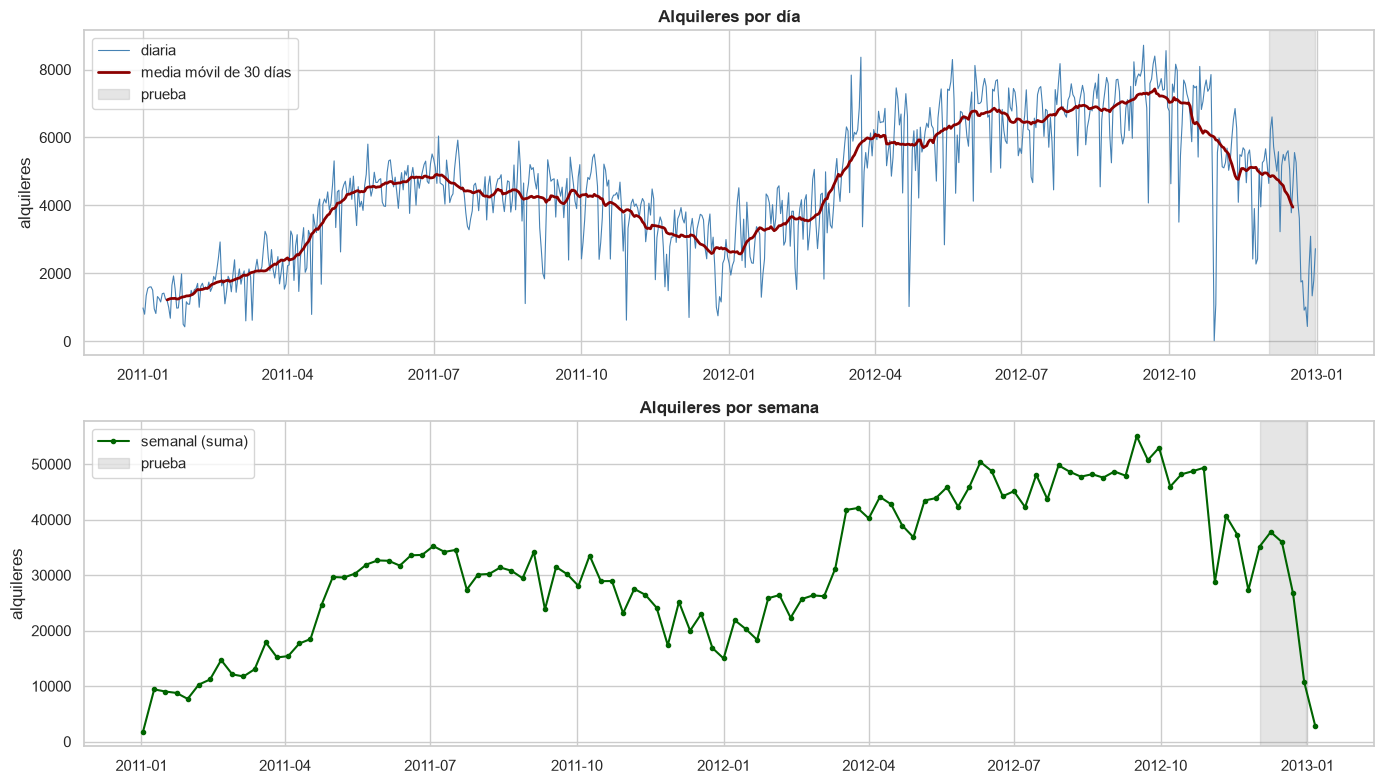

Crecimiento de 2011 a 2012: 64.9%


In [8]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 8))
ejes[0].plot(day.index, day["cnt"], lw=0.8, color="steelblue", label="diaria")
ejes[0].plot(day.index, day["cnt"].rolling(30, center=True).mean(), lw=2, color="darkred", label="media móvil de 30 días")
semanal = day["cnt"].resample("W").sum()
ejes[1].plot(semanal.index, semanal, marker="o", ms=3, color="darkgreen", label="semanal (suma)")
for ax, titulo in zip(ejes, ["Alquileres por día", "Alquileres por semana"]):
    ax.axvspan(INICIO_PRUEBA, FIN_PRUEBA, color="gray", alpha=0.2, label="prueba")
    ax.set(title=titulo, ylabel="alquileres"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIGURAS / "serie_diaria.png", dpi=120, bbox_inches="tight"); plt.show()

anual = day.groupby(day.index.year)["cnt"].agg(["sum", "mean"])
print(f"Crecimiento de 2011 a 2012: {anual['sum'].iloc[1] / anual['sum'].iloc[0] - 1:.1%}")

La serie combina una **tendencia creciente** (el sistema gana usuarios de un año al otro) con una **estacionalidad anual** marcada: la demanda sube en primavera, alcanza su máximo en verano y cae en invierno. La serie semanal suaviza el ruido diario y deja ver la misma forma en los dos años, con un nivel más alto en 2012. El periodo de prueba cae en la bajada invernal y termina con la semana de Navidad.

## 5. Patrones por hora, día de la semana, mes y estación

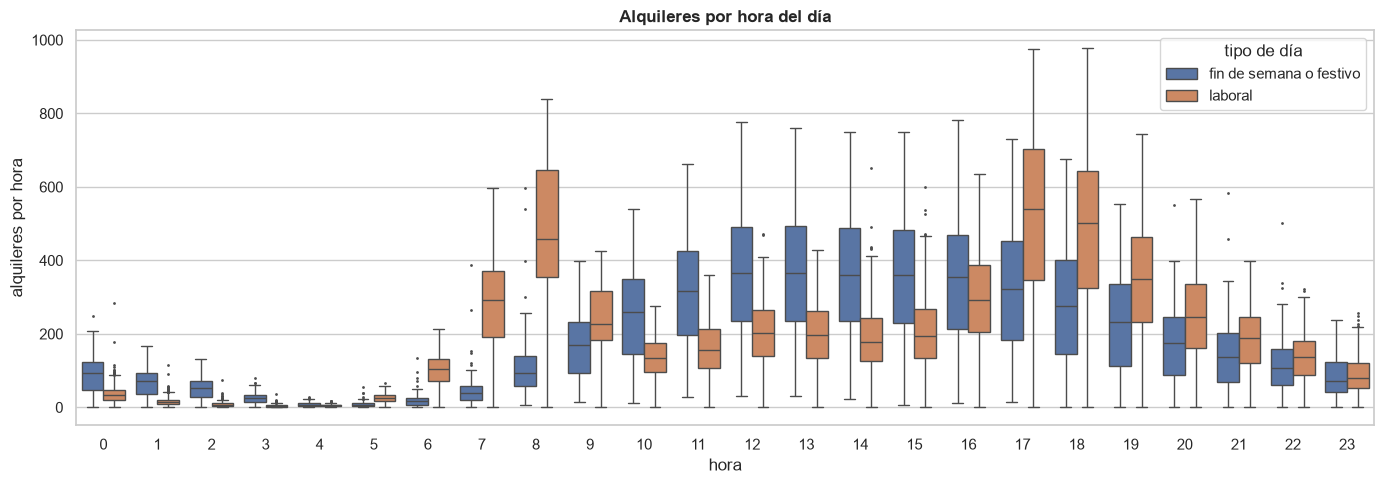

tipo de día,fin de semana o festivo,laboral
hr,,
3,25.00,4.00
8,94.00,459.00
12,367.00,201.00
17,322.00,539.00
18,276.00,503.00


In [9]:
hp = h.copy()
hp["tipo de día"] = np.where(hp["workingday"] == 1, "laboral", "fin de semana o festivo")
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=hp, x="hr", y="cnt", hue="tipo de día", fliersize=1, ax=ax)
ax.set(title="Alquileres por hora del día", xlabel="hora", ylabel="alquileres por hora")
plt.tight_layout(); plt.show()
hp.groupby(["tipo de día", "hr"])["cnt"].median().unstack(0).loc[[3, 8, 12, 17, 18]]

El perfil horario depende del tipo de día. En los días laborales hay dos picos, a las 8:00 y a las 17:00–18:00, propios de los viajes al trabajo; en fines de semana y festivos hay una sola meseta entre las 11:00 y las 17:00. La madrugada es la hora de menor uso en ambos casos. Por eso los modelos horarios necesitan la hora, el tipo de día y su combinación (los árboles la aprenden; un modelo lineal no).

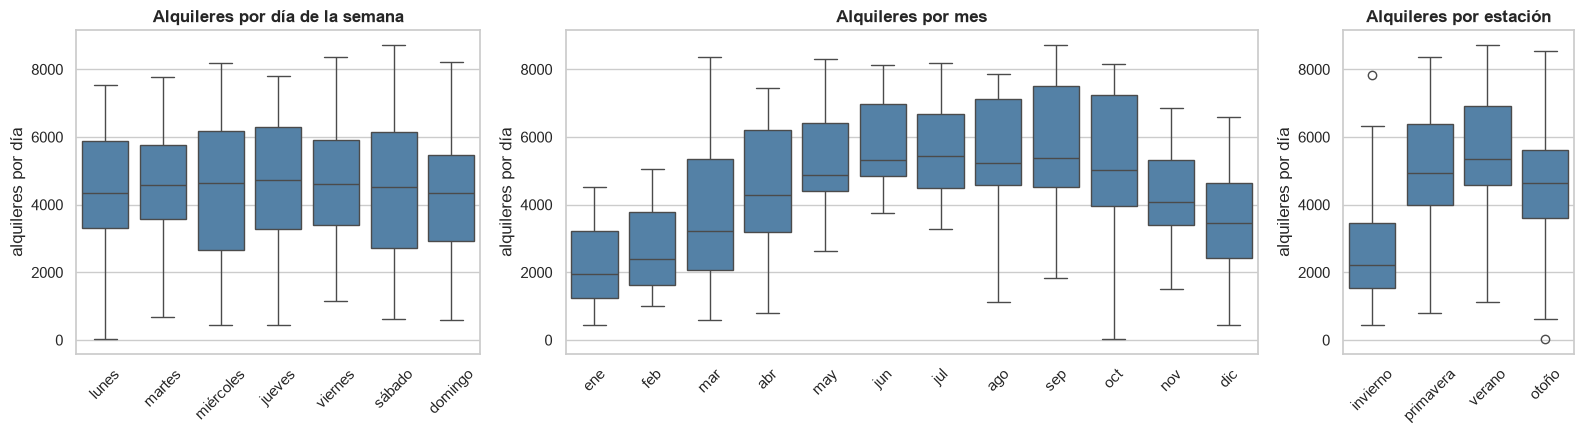

dia                                                         \
           lunes   martes miércoles   jueves  viernes   sábado  domingo   
mediana 4,359.00 4,576.50  4,642.50 4,721.00 4,601.50 4,521.00 4,334.00   

        estacion                              
        invierno primavera   verano    otoño  
mediana 2,209.00  4,941.50 5,353.50 4,634.50

In [10]:
dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
estaciones = {1: "invierno", 2: "primavera", 3: "verano", 4: "otoño"}
dp = day.assign(dia=pd.Categorical(np.array(dias)[day.index.day_of_week], dias),
                mes=pd.Categorical(np.array(meses)[day.index.month - 1], meses),
                estacion=pd.Categorical(day["season"].map(estaciones), list(estaciones.values())))
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [7, 12, 4]})
for ax, col, titulo in zip(ejes, ["dia", "mes", "estacion"], ["día de la semana", "mes", "estación"]):
    sns.boxplot(data=dp, x=col, y="cnt", color="steelblue", ax=ax)
    ax.set(title=f"Alquileres por {titulo}", xlabel="", ylabel="alquileres por día")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
pd.concat({c: dp.groupby(c, observed=True)["cnt"].median() for c in ["dia", "estacion"]}).rename("mediana").to_frame().T

- **Día de la semana:** las medianas son parecidas; el total diario cambia poco entre días, aunque su perfil horario cambia mucho. El efecto semanal es más claro en la composición de usuarios (sección 7).
- **Mes:** curva en forma de campana, con mínimo en enero y febrero y máximo entre junio y septiembre.
- **Estación:** el verano y el otoño concentran la mayor demanda y el invierno la menor. En este dataset `season` sigue el calendario astronómico (el invierno empieza el 21 de diciembre), así que el periodo de prueba mezcla otoño e invierno.

## 6. Correlaciones

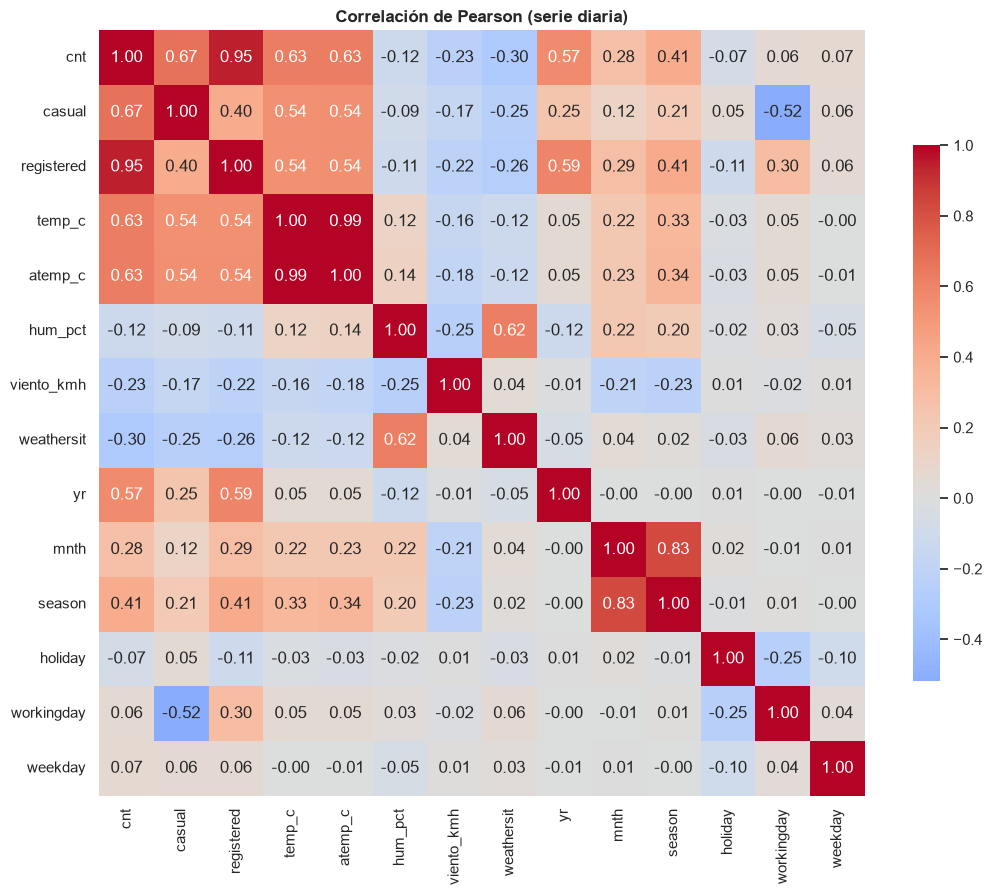

,r con cnt
atemp_c,0.63
temp_c,0.63
yr,0.57
season,0.41
weathersit,-0.30
mnth,0.28
viento_kmh,-0.23
hum_pct,-0.12
holiday,-0.07
weekday,0.07


In [11]:
cols = ["cnt", "casual", "registered", "temp_c", "atemp_c", "hum_pct", "viento_kmh",
        "weathersit", "yr", "mnth", "season", "holiday", "workingday", "weekday"]
corr = day[cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlación de Pearson (serie diaria)")
plt.tight_layout(); plt.show()
corr["cnt"].drop(["cnt", "casual", "registered"]).sort_values(key=abs, ascending=False).to_frame("r con cnt")

- La **temperatura** es la variable más asociada a la demanda (r ≈ 0,63), seguida del año (tendencia) y de la estación.
- `temp_c` y `atemp_c` están casi perfectamente correlacionadas (r ≈ 0,99): incluir ambas en un modelo lineal o en SARIMAX genera multicolinealidad sin aportar información. Se usa solo `temp_c`.
- La situación del tiempo, la humedad y el viento tienen correlación negativa: la lluvia y el viento reducen el uso.
- `casual` y `registered` suman `cnt`, así que nunca se usan como variables de entrada: serían una fuga directa del objetivo.

## 7. Usuarios casuales frente a registrados

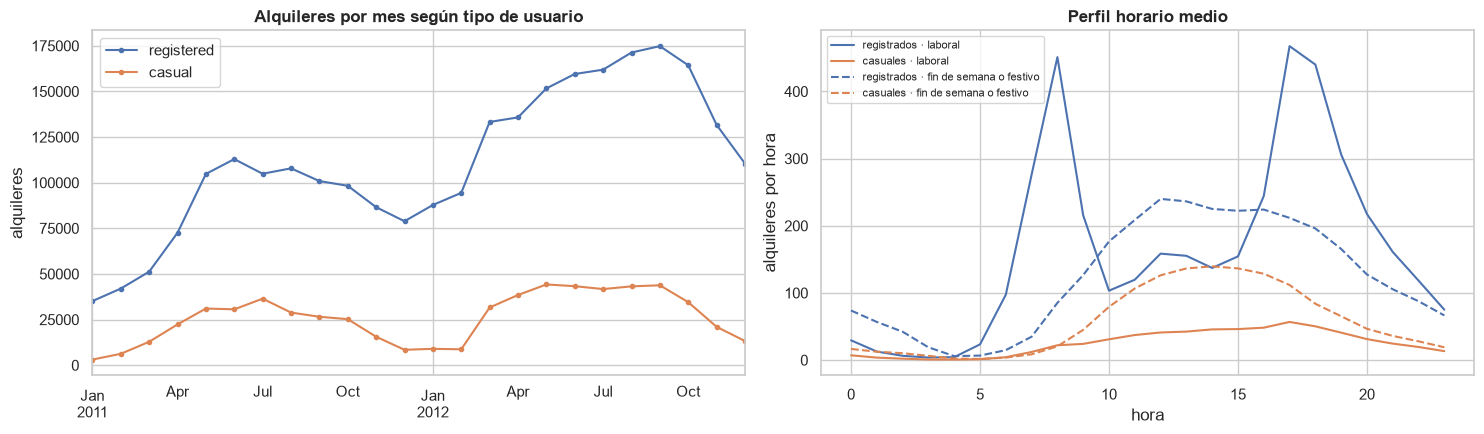

,% casual,% registered
tipo de día,,
fin de semana o festivo,31.70,68.30
laboral,13.20,86.80


In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
mensual = day[["registered", "casual"]].resample("MS").sum()
mensual.plot(ax=ejes[0], marker="o", ms=3)
ejes[0].set(title="Alquileres por mes según tipo de usuario", xlabel="", ylabel="alquileres")
perfil = hp.groupby(["tipo de día", "hr"])[["casual", "registered"]].mean()
for (tipo, estilo) in [("laboral", "-"), ("fin de semana o festivo", "--")]:
    ejes[1].plot(perfil.loc[tipo, "registered"], estilo, color="C0", label=f"registrados · {tipo}")
    ejes[1].plot(perfil.loc[tipo, "casual"], estilo, color="C1", label=f"casuales · {tipo}")
ejes[1].set(title="Perfil horario medio", xlabel="hora", ylabel="alquileres por hora"); ejes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

dp["tipo de día"] = np.where(dp["workingday"] == 1, "laboral", "fin de semana o festivo")
proporcion = dp.groupby("tipo de día")[["casual", "registered"]].sum()
(proporcion.div(proporcion.sum(axis=1), axis=0) * 100).round(1).rename(columns=lambda c: f"% {c}")

Los usuarios registrados son la mayoría de la demanda y explican los picos de entrada y salida del trabajo. Los casuales son un grupo distinto: usan el sistema sobre todo en fines de semana, al mediodía y en los meses cálidos, y su peso en los fines de semana y festivos (32 % de los alquileres) es más del doble que en los días laborales (13 %). El total `cnt` mezcla los dos comportamientos.

## 8. Descomposición de la serie diaria

Se descompone con periodo 7 (estacionalidad semanal) de forma aditiva y multiplicativa.

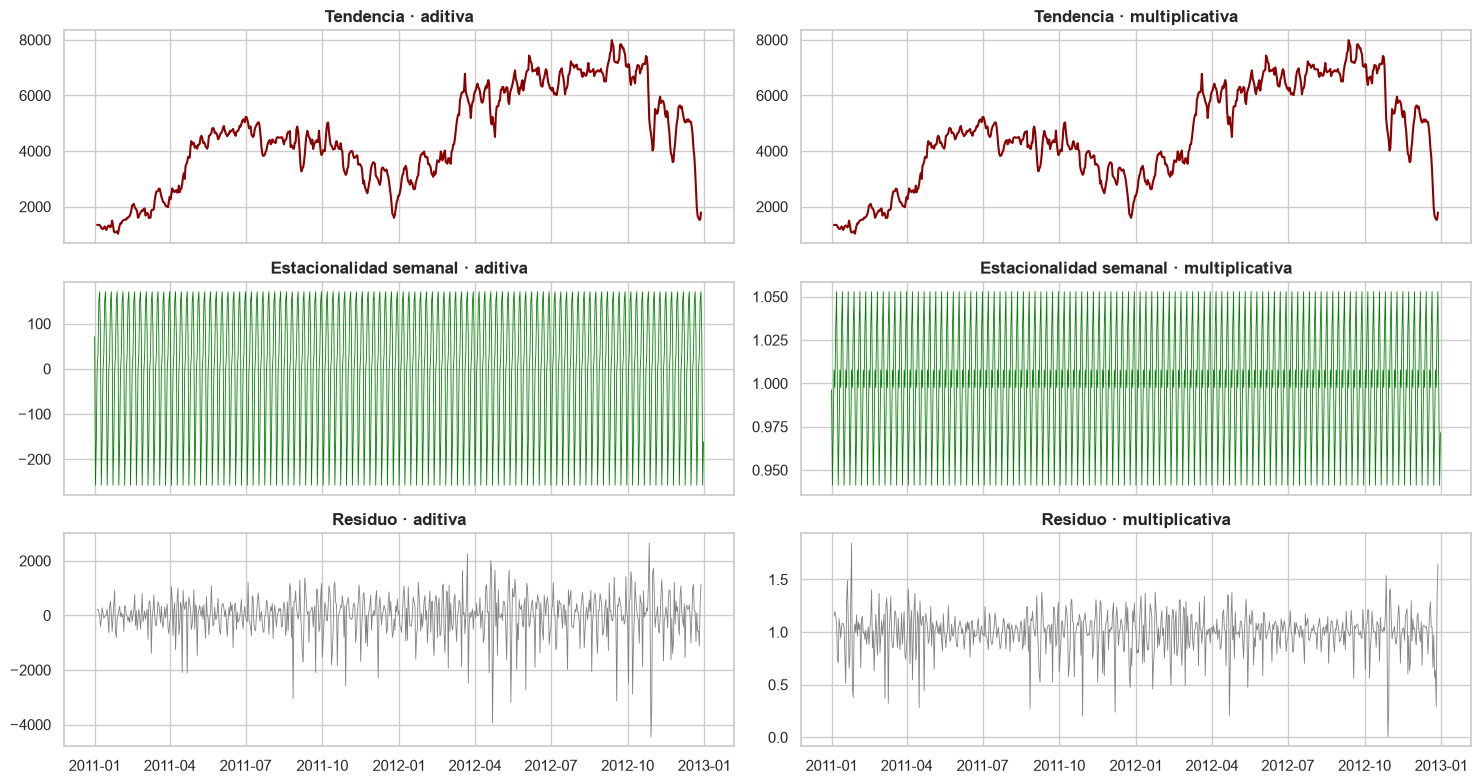

Amplitud semanal aditiva (alquileres): 429
Amplitud semanal multiplicativa (factor): 0.941 – 1.053


,tendencia media,|residuo aditivo| medio
trend,,
cuartil 1 (bajo),"2,230.73",443.62
cuartil 2,"3,968.26",610.75
cuartil 3,"5,128.48",549.91
cuartil 4 (alto),"6,796.98",598.70


In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose

add = seasonal_decompose(day["cnt"], model="additive", period=7)
mul = seasonal_decompose(day["cnt"], model="multiplicative", period=7)
fig, ejes = plt.subplots(3, 2, figsize=(15, 8), sharex=True)
for j, (d, nombre) in enumerate([(add, "aditiva"), (mul, "multiplicativa")]):
    ejes[0, j].plot(d.trend, color="darkred"); ejes[0, j].set_title(f"Tendencia · {nombre}")
    ejes[1, j].plot(d.seasonal, color="green", lw=0.6); ejes[1, j].set_title(f"Estacionalidad semanal · {nombre}")
    ejes[2, j].plot(d.resid, color="gray", lw=0.6); ejes[2, j].set_title(f"Residuo · {nombre}")
plt.tight_layout(); plt.show()

print("Amplitud semanal aditiva (alquileres):", f"{add.seasonal.max() - add.seasonal.min():,.0f}")
print("Amplitud semanal multiplicativa (factor):", f"{mul.seasonal.min():.3f} – {mul.seasonal.max():.3f}")
nivel = pd.qcut(add.trend, 4, labels=["cuartil 1 (bajo)", "cuartil 2", "cuartil 3", "cuartil 4 (alto)"])
pd.DataFrame({"tendencia media": add.trend.groupby(nivel, observed=True).mean(),
              "|residuo aditivo| medio": add.resid.abs().groupby(nivel, observed=True).mean()})

La tendencia de ambas descomposiciones reproduce el ciclo anual y el crecimiento de 2012. La componente semanal es pequeña frente a la tendencia: unos 430 alquileres de amplitud en la forma aditiva, o entre −6 % y +5 % en la multiplicativa. El día de la semana importa poco en el total diario. El residuo absoluto crece con el nivel (de unos 440 alquileres en el cuartil más bajo de la tendencia a unos 600 en los altos), pero mucho menos que proporcionalmente, así que ninguna de las dos formas domina con claridad; la aditiva es suficiente y es la que asumen los modelos SARIMA. En ambos casos el residuo conserva mucha variación, en buena parte del clima, que los modelos con exógenas intentan capturar.

## 9. Autocorrelación y estacionariedad

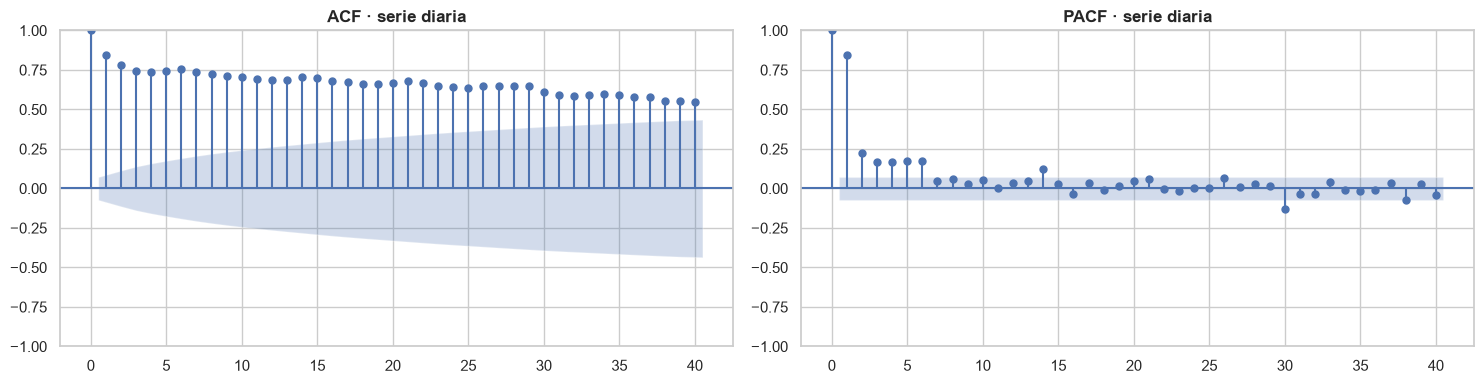

,estadístico ADF,p-valor,crítico 5 %,conclusión
serie,,,,
original,-1.88,0.34,-2.87,no estacionaria
primera diferencia,-11.78,0.00,-2.87,estacionaria


In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

fig, ejes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(day["cnt"], lags=40, ax=ejes[0], title="ACF · serie diaria")
plot_pacf(day["cnt"], lags=40, ax=ejes[1], title="PACF · serie diaria", method="ywm")
plt.tight_layout(); plt.show()

def adf(serie, nombre):
    est, p, rezagos, n, criticos, _ = adfuller(serie.dropna())
    return {"serie": nombre, "estadístico ADF": est, "p-valor": p, "crítico 5 %": criticos["5%"],
            "conclusión": "estacionaria" if p < 0.05 else "no estacionaria"}

pd.DataFrame([adf(day["cnt"], "original"), adf(day["cnt"].diff(), "primera diferencia")]).set_index("serie")

La ACF de la serie original decae muy despacio y la PACF tiene un primer rezago cercano a 1: es la firma de una serie con tendencia, no estacionaria. La prueba ADF lo confirma: no se rechaza la raíz unitaria en la serie original (p ≈ 0,34), y sí en la primera diferencia (p prácticamente 0). Por eso los modelos ARIMA del notebook 02 usan **d = 1**.

## Resumen

- Datos íntegros y coherentes entre archivos; las 165 horas faltantes son horas sin alquileres y se imputan con 0.
- La humedad del 2011-03-10 es una falla del sensor y se imputa.
- Demanda con tendencia creciente, ciclo anual, perfil horario distinto entre días laborales y no laborales, y fuerte dependencia de la temperatura.
- Serie diaria no estacionaria; estacionaria tras una diferencia.
- Se excluyen `casual`, `registered` (fuga del objetivo) y `atemp_c` (colineal con `temp_c`).